<a href="https://colab.research.google.com/github/rajnandini241013006182-web/Rajnandini6182-AI-ML-Lab/blob/main/LAB_3_AI_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

In [25]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(list(uploaded.keys())[0])

print("Dataset loaded successfully!")

print(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

Saving stroke_processed_5k.csv to stroke_processed_5k (2).csv
Dataset loaded successfully!
   gender       age  hypertension  heart_disease  ever_married  work_type  \
0       1  1.051434             0              1             1          2   
1       0  0.786070             0              0             1          3   
2       1  1.626390             0              1             1          2   
3       0  0.255342             0              0             1          2   
4       0  1.582163             1              0             1          3   

   Residence_type  avg_glucose_level       bmi  smoking_status  stroke  
0               1           2.706375  1.005086               1       1  
1               0           2.121559 -0.098981               2       1  
2               0          -0.005028  0.472536               2       1  
3               1           1.437358  0.719327               3       1  
4               0           1.501184 -0.631531               2       1  

Dataset

In [26]:
# Separate features and target

X = df.drop('stroke', axis=1)
y = df['stroke']

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns

# Numerical preprocessing

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4088, 10)
Testing data: (1022, 10)


In [27]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight='balanced',
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    ),

    "SVM": SVC(
        kernel='rbf',
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    "ANN": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=500,
        early_stopping=True,
        random_state=42
    )
}

results = []
confusion_matrices = {}
roc_data = {}
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    # Create pipeline

    clf = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Train model

    clf.fit(X_train, y_train)

    # Prediction

    y_pred = clf.predict(X_test)

    # Probability prediction

    y_prob = clf.predict_proba(X_test)[:, 1]

    # Performance metrics

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    auc = roc_auc_score(y_test, y_prob)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC-ROC': auc
    })

    # Store confusion matrix

    confusion_matrices[name] = confusion_matrix(
        y_test, y_pred
    )

    # Store ROC data

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    roc_data[name] = (fpr, tpr, auc)

    trained_models[name] = clf

    print(name, "completed successfully!")


Training: Logistic Regression
Logistic Regression completed successfully!

Training: Decision Tree
Decision Tree completed successfully!

Training: Random Forest
Random Forest completed successfully!

Training: SVM
SVM completed successfully!

Training: ANN
ANN completed successfully!



MODEL PERFORMANCE COMPARISON
                 Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
0  Logistic Regression    0.7515     0.1408    0.80    0.2395   0.8387
1        Decision Tree    0.9266     0.1212    0.08    0.0964   0.5251
2        Random Forest    0.9501     0.0000    0.00    0.0000   0.7877
3                  SVM    0.7358     0.1181    0.68    0.2012   0.7856
4                  ANN    0.9511     0.0000    0.00    0.0000   0.5410


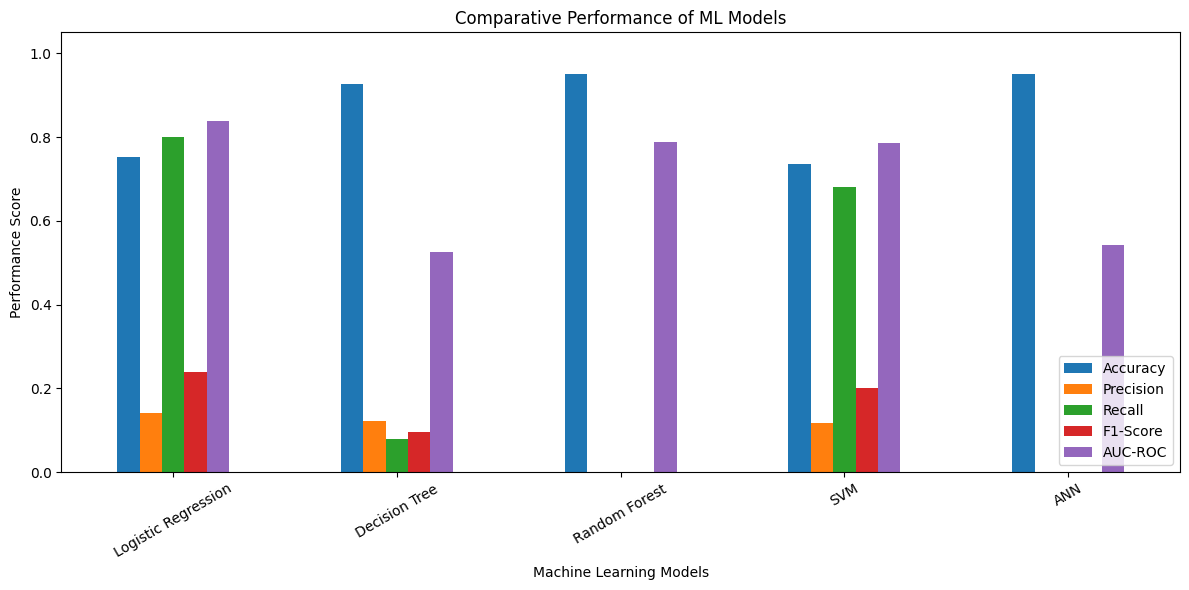

In [28]:
results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")

print(results_df.round(4))

# Display as a graph

results_df.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Comparative Performance of ML Models")
plt.ylabel("Performance Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=30)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

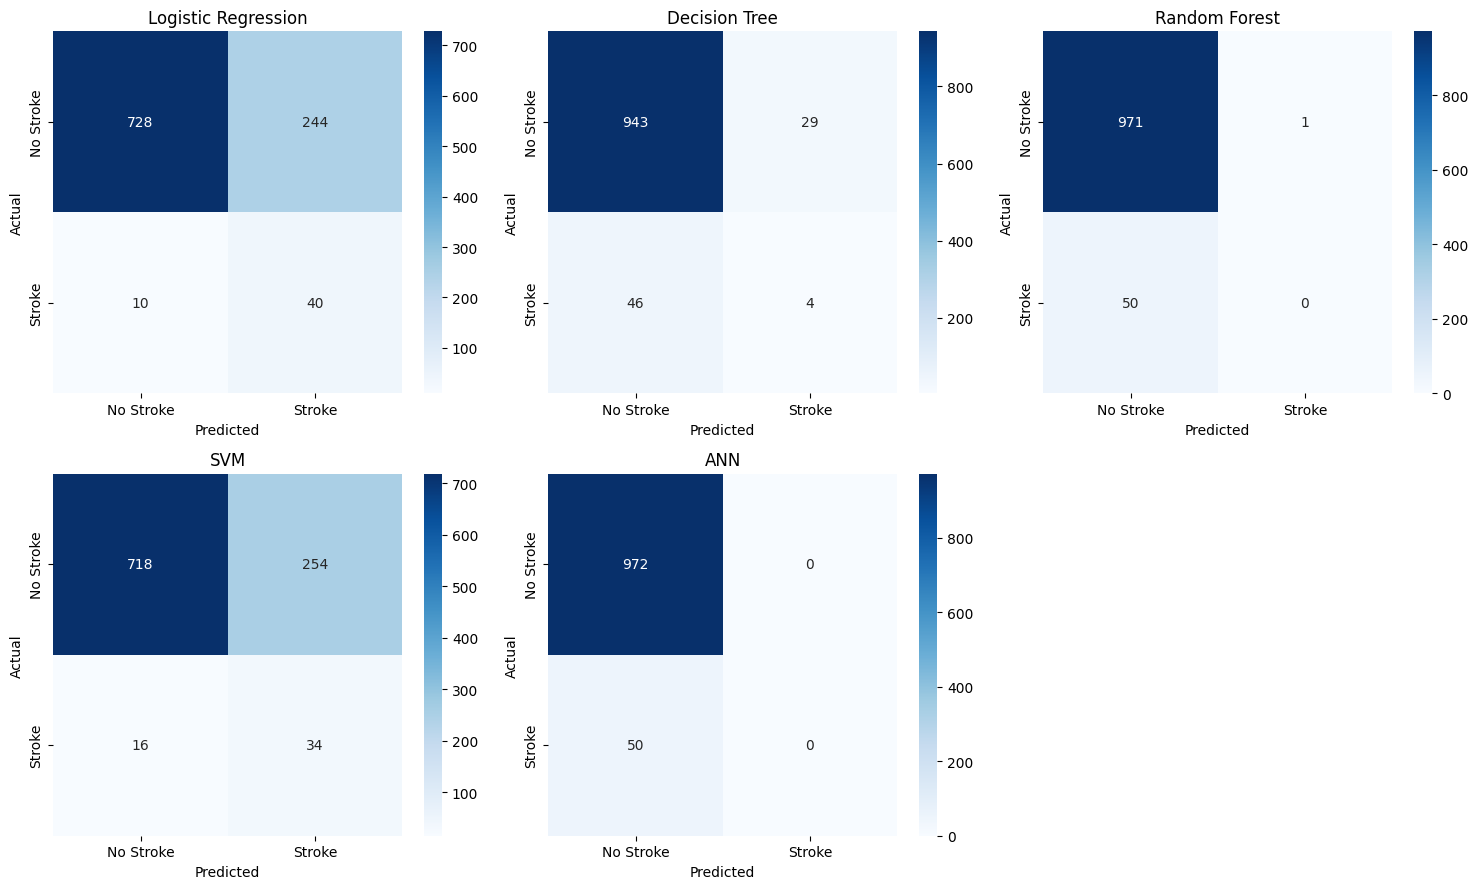

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes = axes.flatten()

for i, (name, cm) in enumerate(
    confusion_matrices.items()
):

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Stroke', 'Stroke'],
        yticklabels=['No Stroke', 'Stroke'],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

# Remove unused subplot

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()


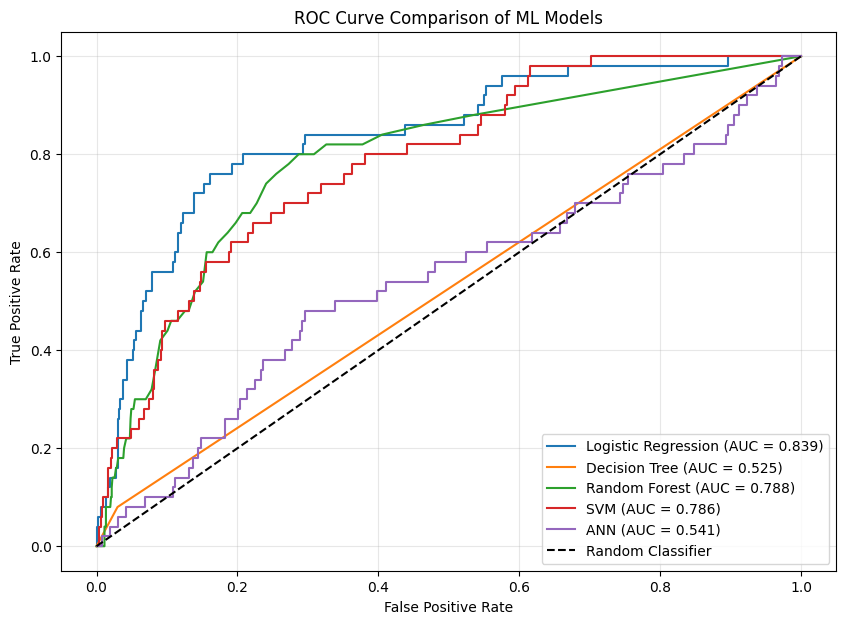

In [31]:
plt.figure(figsize=(10, 7))

for name, (fpr, tpr, auc) in roc_data.items():

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison of ML Models")

plt.legend(loc='lower right')

plt.grid(alpha=0.3)

plt.show()

In [32]:
# Sort models according to AUC-ROC

top3_models = results_df.sort_values(
    by='AUC-ROC',
    ascending=False
).head(3)

print("\nTOP 3 MACHINE LEARNING MODELS")

print(top3_models.round(4))


TOP 3 MACHINE LEARNING MODELS
                 Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
0  Logistic Regression    0.7515     0.1408    0.80    0.2395   0.8387
2        Random Forest    0.9501     0.0000    0.00    0.0000   0.7877
3                  SVM    0.7358     0.1181    0.68    0.2012   0.7856


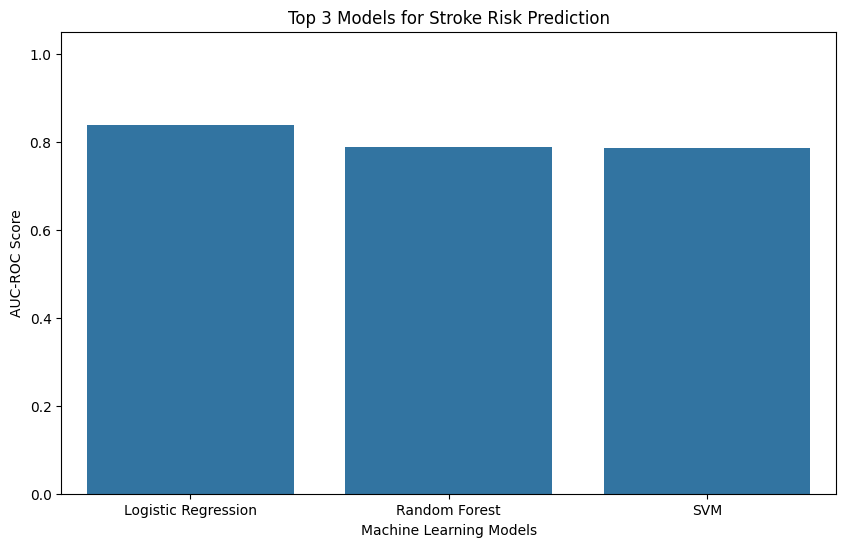

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top3_models,
    x='Model',
    y='AUC-ROC'
)

plt.title("Top 3 Models for Stroke Risk Prediction")

plt.xlabel("Machine Learning Models")
plt.ylabel("AUC-ROC Score")

plt.ylim(0, 1.05)

plt.show()



In [34]:
print("\nTOP 3 MODEL COMPARISON")

for model_name in top3_models['Model']:

    print("\nModel:", model_name)

    model = trained_models[model_name]

    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=['No Stroke', 'Stroke'],
        zero_division=0
    ))


TOP 3 MODEL COMPARISON

Model: Logistic Regression
              precision    recall  f1-score   support

   No Stroke       0.99      0.75      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.55      1022
weighted avg       0.95      0.75      0.82      1022


Model: Random Forest
              precision    recall  f1-score   support

   No Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022


Model: SVM
              precision    recall  f1-score   support

   No Stroke       0.98      0.74      0.84       972
      Stroke       0.12      0.68      0.20        50

    accuracy                           0.74      1022
   macro avg       0.55      0.71      0.5

In [35]:
best_model_name = top3_models.iloc[0]['Model']

print("\nFINAL RESULT")

print("Best Performing Model:", best_model_name)

print("\nPerformance Parameters:")

print(
    results_df[
        results_df['Model'] == best_model_name
    ].round(4).to_string(index=False)
)

print("\nTop Three Models:")

print(top3_models[
    ['Model', 'Accuracy', 'Precision',
     'Recall', 'F1-Score', 'AUC-ROC']
].round(4).to_string(index=False))


FINAL RESULT
Best Performing Model: Logistic Regression

Performance Parameters:
              Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Logistic Regression    0.7515     0.1408     0.8    0.2395   0.8387

Top Three Models:
              Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Logistic Regression    0.7515     0.1408    0.80    0.2395   0.8387
      Random Forest    0.9501     0.0000    0.00    0.0000   0.7877
                SVM    0.7358     0.1181    0.68    0.2012   0.7856


In [36]:
results_df.to_csv(
    'Stroke_ML_Comparative_Results.csv',
    index=False
)

print("Results saved successfully!")

Results saved successfully!
